# BME 6120 Project 4 — cfRNA classification results

[Moore et al. (2025)](https://doi.org/10.1038/s41467-025-62685-y) studied whether plasma cell-free RNA (cfRNA) can distinguish pancreatic ductal adenocarcinoma (PDAC) from other diagnoses in high-risk and symptomatic patients sampled before diagnostic evaluation. We reproduced the pooled BCC result from Figure 5, then tested whether fitting normalization only on CEDAR changes discrimination. A fixed-panel control holds the original 29 genes constant while changing normalization.

Run with a Python 3 kernel from the repository root or the `notebooks/` directory. The analysis cells use the standard library, Matplotlib, and IPython. Use JupyterLab to run interactively or nbconvert to execute from the command line. This notebook reads saved CSVs and draws ROC curves from prediction scores. It does not require R or the original expression matrix.

In [1]:
import csv
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
results = root / "results"
extension = results / "extension"
control = extension / "fixed_panel"


def read_rows(path):
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path.relative_to(root)}. See README.md for the analysis run order.")
    with path.open(encoding="utf-8", newline="") as handle:
        return list(csv.DictReader(handle))


section1 = read_rows(results / "figure5_bcc_metrics.csv")[0]
section2 = read_rows(extension / "normalization_summary.csv")[0]
models = {row["Model"]: row for row in read_rows(control / "model_aurocs.csv")}
contrasts = read_rows(control / "paired_auc_differences.csv")
predictions = read_rows(control / "bcc_predictions.csv")
published = float(section1["Published_AUROC"])
reproduced = float(section1["BCC_AUROC"])
n_cedar = int(section1["CEDAR_samples"])
n_bcc = int(section1["BCC_samples"])
n_bcc_pdac = sum(row["TrueLabel"] == "PDAC" for row in predictions)
assert len(predictions) == len({row["SeqID"] for row in predictions}) == n_bcc
assert {row["TrueLabel"] for row in predictions} == {"PDAC", "notPDAC"}

## Cohorts and Section 1 reproduction

CEDAR was used for training and gene selection. BCC was the held-out evaluation cohort. The negative class includes benign pancreatic conditions, pancreatitis, IPMN, and other cancers.

We reused the authors’ cfRNA normalization and TMM with both cohorts pooled. The CEDAR variance filter and Wilcoxon FDR filter selected 29 genes. The model log-transformed the selected features, applied SMOTE to training data only, and used the published random forest settings (250 trees, `mtry = 1`, `nodesize = 1`, sampling with replacement, seed 50). The benchmark is the bottom row of [Figure 5](https://pmc.ncbi.nlm.nih.gov/articles/PMC12335587/#Fig5).

In [2]:
display(Markdown(
    "| Cohort | Role | Samples | PDAC | Other diagnoses |\n"
    "| --- | --- | ---: | ---: | ---: |\n"
    f"| CEDAR | Training | {n_cedar} | 20 | {n_cedar - 20} |\n"
    f"| BCC | Validation | {n_bcc} | {n_bcc_pdac} | {n_bcc - n_bcc_pdac} |\n\n"
    f"**Reproduced BCC AUROC {reproduced:.6f}** versus published **{published:.3f}**. "
    "The values agree at the published precision."
))

| Cohort | Role | Samples | PDAC | Other diagnoses |
| --- | --- | ---: | ---: | ---: |
| CEDAR | Training | 153 | 20 | 133 |
| BCC | Validation | 95 | 21 | 74 |

**Reproduced BCC AUROC 0.896075** versus published **0.896**. The values agree at the published precision.

## Section 2 and fixed-panel control

The frozen workflow estimated the cfRNA component medians, TMM reference, and TMM centering constant from CEDAR. It applied the frozen parameters to each BCC sample independently. Reselecting genes retained all 29 original genes and added seven. The fixed-panel control used the same frozen normalization with the original 29 genes. Cohorts, SMOTE, the forest settings, and the model seed were held constant. BCC labels were used only for scoring the predictions against observed diagnoses.

In [3]:
model_labels = {
    "Pooled_29": "Pooled normalization, original panel",
    "Frozen_36": "Frozen normalization, reselected panel",
    "Frozen_29": "Frozen normalization, original panel",
}
aurocs = {key: float(models[key]["BCC_AUROC"]) for key in model_labels}
lines = ["| Model | Genes | BCC AUROC |", "| --- | ---: | ---: |"]
for key, label in model_labels.items():
    lines.append(f"| {label} | {models[key]['Genes']} | {aurocs[key]:.6f} |")
display(Markdown("\n".join(lines)))

lines = [
    "| Contrast | AUROC difference | Paired bootstrap 95% CI |",
    "| --- | ---: | ---: |",
]
for row in contrasts:
    delta = float(row["AUROC_difference"])
    lower = float(row["CI95_lower"])
    upper = float(row["CI95_upper"])
    lines.append(f"| {row['Contrast']} | {delta:+.6f} | [{lower:+.6f}, {upper:+.6f}] |")
display(Markdown("\n".join(lines)))
display(Markdown(
    f"The percentile intervals use {int(section2['Bootstrap_replicates']):,} paired, "
    f"case/control-stratified BCC resamples (seed {section2['Bootstrap_seed']})."
))

| Model | Genes | BCC AUROC |
| --- | ---: | ---: |
| Pooled normalization, original panel | 29 | 0.896075 |
| Frozen normalization, reselected panel | 36 | 0.900257 |
| Frozen normalization, original panel | 29 | 0.892214 |

| Contrast | AUROC difference | Paired bootstrap 95% CI |
| --- | ---: | ---: |
| Frozen 29 minus Pooled 29 | -0.003861 | [-0.036036, +0.023810] |
| Frozen 36 minus Frozen 29 | +0.008044 | [-0.027992, +0.041184] |
| Frozen 36 minus Pooled 29 | +0.004183 | [-0.037975, +0.042793] |

The percentile intervals use 10,000 paired, case/control-stratified BCC resamples (seed 6120).

## BCC ROC curves

The plots use saved BCC predictions aligned by sample ID. Every curve treats higher scores as stronger evidence for PDAC. Samples with tied scores cross the same threshold together.

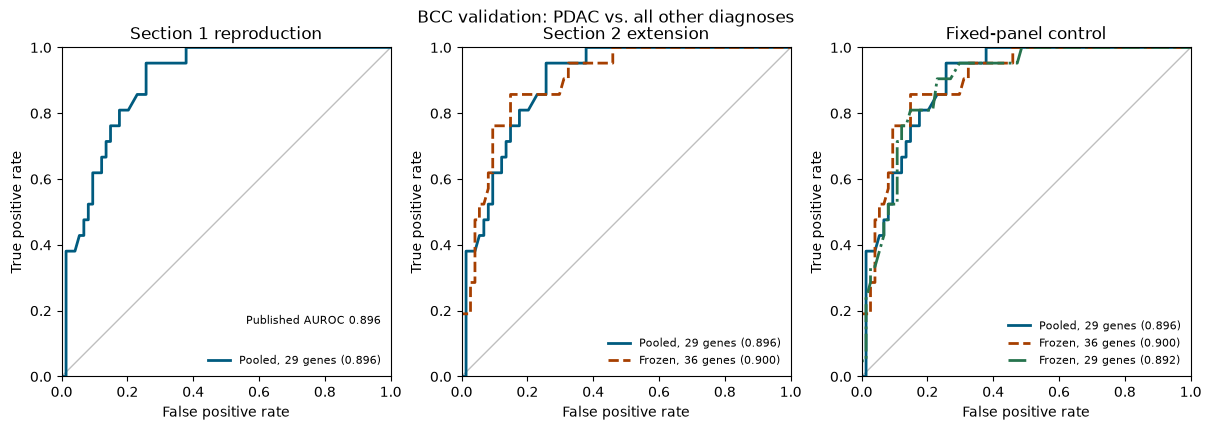

In [4]:
def roc_points(model):
    ordered = sorted(predictions, key=lambda row: float(row[model]), reverse=True)
    false_positive_rate, true_positive_rate = [0.0], [0.0]
    true_positives = false_positives = 0
    for index, row in enumerate(ordered):
        if row["TrueLabel"] == "PDAC":
            true_positives += 1
        else:
            false_positives += 1
        if index + 1 == len(ordered) or float(row[model]) != float(ordered[index + 1][model]):
            true_positive_rate.append(true_positives / n_bcc_pdac)
            false_positive_rate.append(false_positives / (n_bcc - n_bcc_pdac))
    auc = sum(
        (x1 - x0) * (y1 + y0) / 2
        for x0, x1, y0, y1 in zip(
            false_positive_rate, false_positive_rate[1:], true_positive_rate, true_positive_rate[1:]
        )
    )
    if abs(auc - aurocs[model]) > 1e-10:
        raise ValueError(f"ROC area does not match the saved AUROC for {model}")
    return false_positive_rate, true_positive_rate


styles = {
    "Pooled_29": ("#005B7F", "-", "Pooled, 29 genes"),
    "Frozen_36": ("#A63F00", "--", "Frozen, 36 genes"),
    "Frozen_29": ("#26734D", "-.", "Frozen, 29 genes"),
}
panels = [
    ("Section 1 reproduction", ["Pooled_29"]),
    ("Section 2 extension", ["Pooled_29", "Frozen_36"]),
    ("Fixed-panel control", list(model_labels)),
]
curves = {key: roc_points(key) for key in model_labels}
fig, axes = plt.subplots(1, 3, figsize=(12, 4.1), layout="constrained")
fig.suptitle("BCC validation: PDAC vs. all other diagnoses")
for ax, (title, keys) in zip(axes, panels):
    ax.plot([0, 1], [0, 1], color="0.75", linewidth=1)
    for key in keys:
        color, linestyle, label = styles[key]
        ax.plot(*curves[key], color=color, linestyle=linestyle, linewidth=2,
                label=f"{label} ({aurocs[key]:.3f})")
    ax.set(title=title, xlabel="False positive rate", ylabel="True positive rate",
           xlim=(0, 1), ylim=(0, 1), aspect="equal")
    if len(keys) == 1:
        ax.text(0.97, 0.16, f"Published AUROC {published:.3f}", ha="right",
                transform=ax.transAxes, fontsize=8)
    ax.legend(loc="lower right", fontsize=8, frameon=False)
plt.show()

## Discussion and conclusion

The point estimates show a small decrease from freezing normalization at fixed features and an increase from using the reselected panel under frozen normalization. All three intervals span zero. The data leave both effects uncertain.

The pooled workflow lets BCC expression influence scaling and, indirectly, the CEDAR-selected panel. The frozen 29-gene control inherits that panel. The reselected frozen workflow estimates normalization and selects features in CEDAR alone. The bootstrap conditions on the fitted models and reflects sampling uncertainty in one validation cohort with 21 PDAC cases. These results address discrimination and do not establish calibration or clinical utility.

The reproduction matches the published AUROC to three decimals and the extension demonstrates a procedure for scoring samples independently of the validation cohort. See [the final audit](../docs/final_results_summary.md) for the complete methods and links to the original ROC PDFs.